# C3 Photosynthesis Modelling Practical
**English edition · 90 minutes**

Investigate how enzyme capacity, metabolic connectivity and environmental inputs influence
C3 photosynthesis. Read the principles, run an example, complete a short programming exercise,
and assess the result using mass balances and physiological reasoning.

The practical uses a physiological revision of the supplied 35-state C3 carbon-metabolism
model, including the Calvin–Benson cycle, photorespiration and sucrose metabolism.
The default model uses a common Rubisco–RuBP occupancy for carboxylation and oxygenation,
includes a lumped cost of ammonia reassimilation, and reports net CO₂ exchange after respiration.
Assimilation is computed from the network; its response is not forced to be monotonic.

| Module | Programming task | Main output |
|---|---|---|
| [1. Enzymes and reaction kinetics](01_Enzymes_and_Kinetics.ipynb) | Change enzyme capacity; implement an SBPase rate equation | Reaction flux and net assimilation |
| [2. Metabolic networks](02_Metabolic_Networks.ipynb) | Add a parallel reaction; verify its stoichiometry | Circular pathway diagram and metabolite trajectories |
| [3. Environmental and light responses](03_Environmental_Responses.ipynb) | Define a sunfleck; compare equal-light-dose treatments | Dynamic responses and cumulative CO₂ uptake |

[Worked solutions](04_Worked_Solutions.ipynb) · [Physiological consistency checks](05_Physiological_Checks.ipynb)

In [ ]:
# Locate c3_model for both local Jupyter and Kaggle sessions.
import sys
from pathlib import Path

_model_root = None
for _candidate in (Path.cwd(), *Path.cwd().parents):
    if (_candidate / "c3_model" / "__init__.py").is_file():
        _model_root = _candidate
        break

if _model_root is None:
    _matches = sorted(Path("/kaggle/input").glob("**/c3_model/__init__.py"))
    if _matches:
        _model_root = _matches[0].parent.parent

if _model_root is None:
    raise FileNotFoundError(
        "Cannot find c3_model/__init__.py. On Kaggle, add the dataset containing "
        "the complete c3_model folder via Add Input. Locally, start Jupyter "
        "from the project folder or its Course subfolder."
    )

if str(_model_root) not in sys.path:
    sys.path.insert(0, str(_model_root))
print("c3_model directory:", _model_root / "c3_model")


## Learning objectives and schedule
By the end of the practical, you should be able to relate enzyme abundance to maximum reaction
capacity, implement a reversible inhibited rate equation, add a stoichiometrically balanced
reaction, and compare dynamic light treatments using both instantaneous and integrated outputs.

| Time | Activity | Principles / example / exercises / discussion |
|---|---|---|
| 0–5 min | Introduction and execution check | Identify inputs, states and outputs |
| 5–30 min | Module 1: enzymes and kinetics | 7 / 5 / 10 / 3 min |
| 30–55 min | Module 2: metabolic networks | 6 / 6 / 10 / 3 min |
| 55–85 min | Module 3: environmental responses | 6 / 8 / 12 / 4 min |
| 85–90 min | Synthesis and submission | Explain one result using evidence |

**Prerequisites:** basic familiarity with Python variables, lists and functions. Reading all
equations in the model is not required. In `def rate(s): return s / (1 + s)`, `s` is an input,
`return` supplies the output, and `rate(2)` evaluates the function at 2.

**Operation:** select a code cell and press **Shift+Enter**; save with **Ctrl+S**. Every example,
exercise and worked solution is self-contained and can run in a fresh kernel. A `return None`
statement marks an exercise to complete; the uncompleted cell displays guidance rather than
an intentional error. Saved figures are examples, not evidence that your current kernel has
executed the cell. After editing a `.py` module, restart the kernel before running it again.

## Reference conditions
PAR = 1000 µmol photons m⁻² s⁻¹; intercellular CO₂, Ci = 280 ppm; leaf temperature = 25 °C;
O₂ = 21%; Vcmax25 = 80 and Jmax25 = 160 µmol m⁻² s⁻¹.

Declared teaching parameters include kcat25 = 2 s⁻¹, Rd25 = 1 µmol CO₂ m⁻² s⁻¹ and an
ATP Km of 0.1 mM for the lumped reassimilation closure. These are generic assumptions,
not measurements fitted to a particular species or cultivar. NumPy, SciPy, Matplotlib and
JupyterLab are supplied by the hosted classroom; MATLAB is not required to run the practical.

## Execution check
Run the following cell. It should print a net assimilation rate and display two panels.

Execution successful: 35 states; net A at 3000 s = 15.559 µmol CO₂ m⁻² s⁻¹


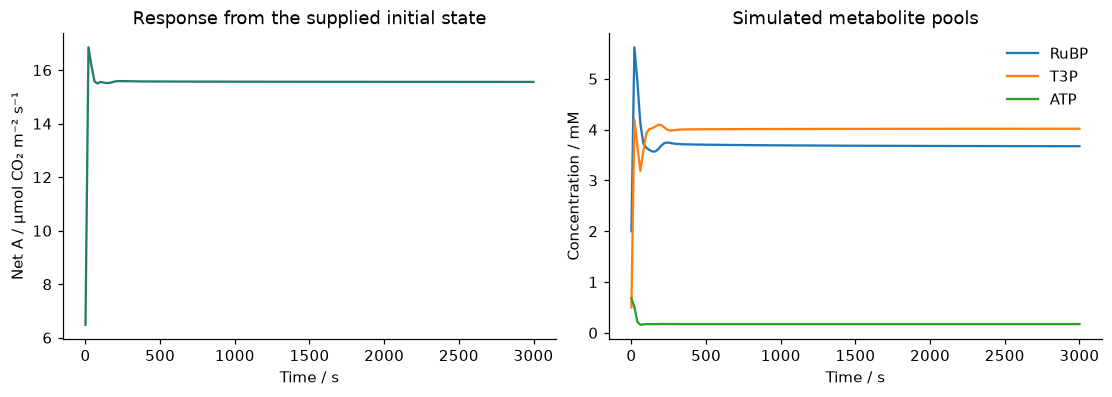

In [ ]:
from c3_model import C3Model, simulate
from c3_model.plots import style
import matplotlib.pyplot as plt
style()

model = C3Model(light=1000, ci=280, temperature=25)  # EDIT: environmental inputs
result = simulate(model, duration=3000)
print(f'Execution successful: 35 states; net A at 3000 s = {result.assimilation[-1]:.3f} µmol CO₂ m⁻² s⁻¹')
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5), constrained_layout=True)
axes[0].plot(result.time, result.assimilation, color='#247c6b')
axes[0].set(xlabel='Time / s', ylabel='Net A / µmol CO₂ m⁻² s⁻¹', title='Response from the supplied initial state')
for name in ['RuBP', 'T3P', 'ATP']:
    axes[1].plot(result.time, result.concentration(name), label=name)
axes[1].set(xlabel='Time / s', ylabel='Concentration / mM', title='Simulated metabolite pools')
axes[1].legend(frameon=False)
plt.show()

## Model interpretation and scope
Net assimilation is $A=30(v_1-v_{131})-R_d$. The original rates are in mM s⁻¹; the source
conversion factor 30 expresses the fluxes per unit leaf area. `result.biochemical_assimilation`
returns the same carbon-flux difference before Rd is subtracted. Respiration is supplied by a
reserve outside the 35-state fast metabolic network; it is not deducted from those pools again.

- Ci is used as a proxy for chloroplast CO₂. Stomatal and mesophyll conductances are not represented.
- Enzyme multipliers change capacity at fixed kcat, activation assumptions and initial pools.
  There is no fixed protein-nitrogen budget or nitrogen reallocation.
- Carboxylation and oxygenation share the same bound-RuBP fraction; PRK uses free RuBP.
  GS/GOGAT are lumped with GDC under a quasi-steady ammonia assumption. ATP cost enters the
  equations; the NADPH equivalent enters the incident-light feasibility check.
- NADPH and some cytosolic cofactors remain buffered. The model does not simulate photosystems,
  NPQ, xanthophyll cycling, dynamic Rubisco activation or measured NADPH induction kinetics.
- The 41 rate-output slots include reserved and diagnostic entries; they are not 41 independent
  operative reactions.

The physiological formulation passed [qualitative consistency checks](05_Physiological_Checks.ipynb)
over the stated parameter domain. This does not establish quantitative agreement with measured
gas exchange. No particular species, cultivar, yield or field treatment has been calibrated.

The default implementation is in `c3_model/physiology.py` and `physiology_equations.py`.
The preserved Python port is in `c3_model/equations.py`. Original authorship is credited
in the Python source; the full GPL licence is in `c3_model/COPYING`.
`C3Model(formulation='original')` is for source regression only and excludes Rd. Compare the two
formulations using the same output definition, not unmatched net and pre-respiration values.

The English edition retains the same numerical equations as the Chinese edition.
Seven numerical trajectory comparisons were identical. All 12 original teaching code
cells were successfully executed in independent fresh kernels before publication;
the three in-module reference-answer cells use the same verified code as Notebook 04.

## Synthesis and submission · 85–90 min
Save your three module notebooks. Submit one completed rate equation with units, the added
reaction's stoichiometry and carbon-balance check, and the cumulative CO₂ uptake for the two
equal-light-dose treatments.

**Exit question:** why does a 50% increase in enzyme capacity not imply a 50% increase in net
assimilation? Support your answer with one numerical comparison and a specific mechanism.
Distinguish a result of this model from a verified biological or agronomic prediction.

## Python source and included environment
This offline Windows edition includes Python, JupyterLab, NumPy, SciPy,
Matplotlib and ipykernel in its private runtime folder. No installation or
website account is needed. Extract the entire ZIP, then double-click
`START_COURSE.bat` in the parent folder. Do not start from inside the ZIP.
Your saved work stays in the Course folder; each student uses their own copy.

| Source | Purpose |
|---|---|
| [model.py](c3_model/model.py) | Model inputs, integration and result access |
| [student_rates.py](c3_model/student_rates.py) | Editable SBPase rate equation |
| [physiology.py](c3_model/physiology.py) | Rubisco occupancy and physiological parameters |
| [physiology_equations.py](c3_model/physiology_equations.py) | Default metabolic equations |
| [equations.py](c3_model/equations.py) | Preserved original Python formulation |
| [matlab.py](c3_model/matlab.py) | Indexing helpers used by the translated equations |
| [plots.py](c3_model/plots.py) | Plot and circular pathway helpers |
| [__init__.py](c3_model/__init__.py) | Public Python interface |

After editing a Python module, restart the notebook kernel before rerunning the code.
Original model copyright (2007) Xin-Guang Zhu and Stephen P. Long, University of Illinois. Python translation and declared physiological revision distributed under GPL-3.0-or-later; see COPYING.
